## 1. Introduction
Comparative Analysis of Optimization Algorithms



2. Import libraries

In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
print(torch.__version__)

2.13.0+cpu
2.13.0+cpu


3. Load dataset

In [5]:
from torchvision import datasets


In [7]:
train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True
)

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

Training samples: 60000
Test samples: 10000
Training samples: 60000
Test samples: 10000


4. Dataset inspection

In [9]:
# Check the shape and labels of the dataset

image, label = train_data[0]

print("Image size:", image.size)
print("Label:", label)
print("Dataset classes:")
print(train_data.classes)

Image size: (28, 28)
Label: 9
Dataset classes:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Image size: (28, 28)
Label: 9
Dataset classes:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


5. Dataset visualization

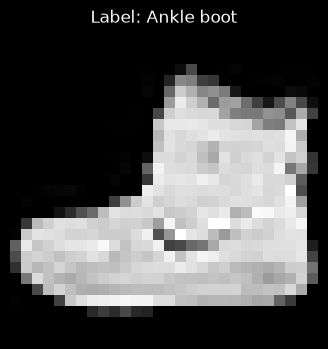

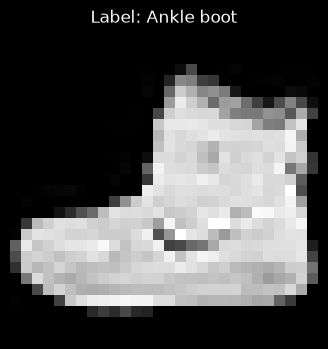

In [11]:
import matplotlib.pyplot as plt

image, label = train_data[0]

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title(f"Label: {train_data.classes[label]}")
plt.axis("off")
plt.show()

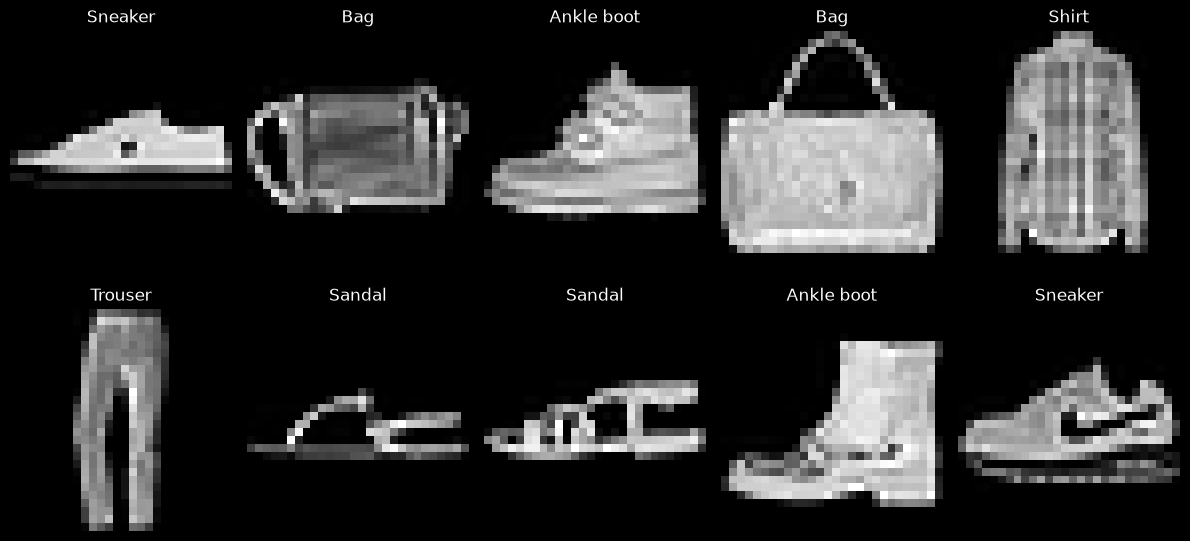

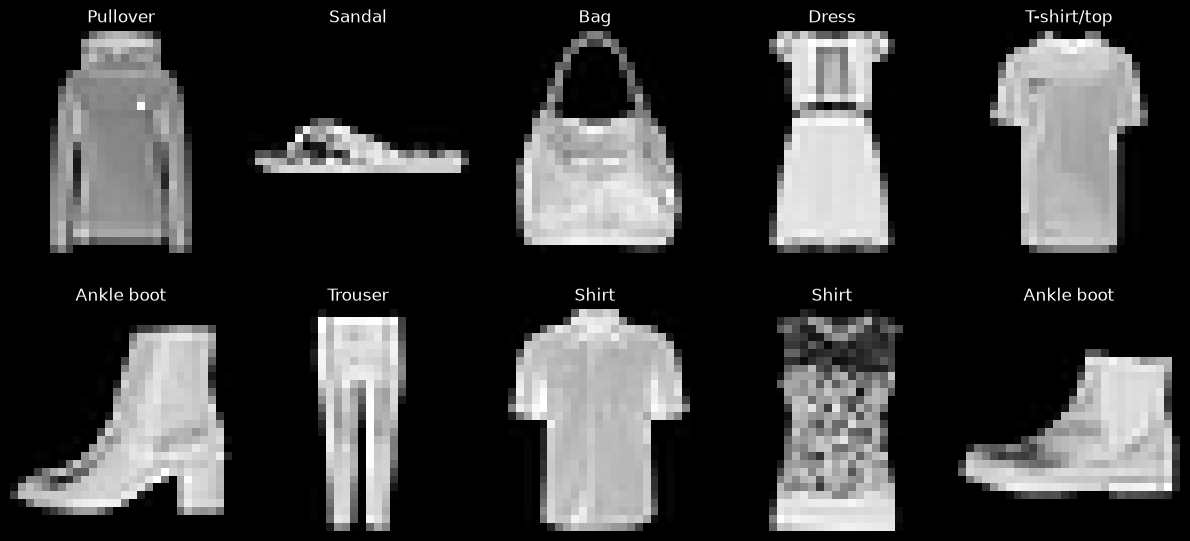

In [13]:
# Visualize 10 random images from the training dataset

import random

plt.figure(figsize=(12, 6))

for i in range(10):
    index = random.randint(0, len(train_data) - 1)
    image, label = train_data[index]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(train_data.classes[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

6. Data Preprocessing

In [15]:
import torch
from torchvision import transforms

In [17]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [19]:
train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

Training samples: 60000
Test samples: 10000
Training samples: 60000
Test samples: 10000


In [21]:
image, label = train_data[0]

print("Image tensor shape:", image.shape)
print("Minimum value:", image.min().item())
print("Maximum value:", image.max().item())
print("Label:", train_data.classes[label])

Image tensor shape: torch.Size([1, 28, 28])
Minimum value: -1.0
Maximum value: 1.0
Label: Ankle boot
Image tensor shape: torch.Size([1, 28, 28])
Minimum value: -1.0
Maximum value: 1.0
Label: Ankle boot


7. Define DNN Model

In [23]:
import torch.nn as nn

class FashionDNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [25]:
model = FashionDNN()

print(model)

FashionDNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
FashionDNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


8. Create DataLoaders

In [27]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

print("Batch size:", batch_size)
print("Number of training batches:", len(train_loader))
print("Number of test batches:", len(test_loader))

Batch size: 64
Number of training batches: 938
Number of test batches: 157
Batch size: 64
Number of training batches: 938
Number of test batches: 157


In [29]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


In [31]:
outputs = model(images)

print("Output shape:", outputs.shape)

Output shape: torch.Size([64, 10])
Output shape: torch.Size([64, 10])


9. Loss Function

In [33]:
criterion = nn.CrossEntropyLoss()

loss = criterion(outputs, labels)

print("Initial loss:", loss.item())

Initial loss: 2.31612229347229
Initial loss: 2.31612229347229


## 10. SGD Experiment
In this experiment, the neural network is trained using the Stochastic Gradient Descent (SGD) optimization algorithm.

In [35]:
# SGD optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [37]:
#Training
def train_model(model, train_loader, test_loader, criterion, optimizer, epochs=30):

    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):

        # Training mode
        model.train()

        running_loss = 0.0

        for images, labels in train_loader:

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update model parameters
            optimizer.step()

            running_loss += loss.item()

        # Average training loss
        epoch_loss = running_loss / len(train_loader)
        train_losses.append(epoch_loss)

        # Evaluation
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:

                outputs = model(images)
                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total
        test_accuracies.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {accuracy:.2f}%"
        )

    return train_losses, test_accuracies

In [ ]:
# бірінші модель оқытамыз
train_losses_sgd, test_accuracies_sgd = train_model(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    epochs=30
)

Epoch [1/30] Loss: 0.9823 Accuracy: 76.60%
Epoch [2/30] Loss: 0.5561 Accuracy: 79.48%
Epoch [3/30] Loss: 0.4882 Accuracy: 82.22%
Epoch [4/30] Loss: 0.4533 Accuracy: 83.22%
Epoch [5/30] Loss: 0.4311 Accuracy: 83.20%
Epoch [6/30] Loss: 0.4138 Accuracy: 84.35%
Epoch [7/30] Loss: 0.3991 Accuracy: 84.76%
Epoch [8/30] Loss: 0.3874 Accuracy: 83.75%
Epoch [9/30] Loss: 0.3768 Accuracy: 85.22%
Epoch [10/30] Loss: 0.3677 Accuracy: 85.27%
Epoch [11/30] Loss: 0.3594 Accuracy: 85.64%
Epoch [12/30] Loss: 0.3512 Accuracy: 85.99%
Epoch [13/30] Loss: 0.3445 Accuracy: 85.17%
Epoch [14/30] Loss: 0.3381 Accuracy: 84.74%
Epoch [15/30] Loss: 0.3326 Accuracy: 86.11%
Epoch [16/30] Loss: 0.3258 Accuracy: 85.41%
Epoch [17/30] Loss: 0.3201 Accuracy: 86.16%
Epoch [18/30] Loss: 0.3160 Accuracy: 87.06%
Epoch [19/30] Loss: 0.3111 Accuracy: 86.67%
Epoch [20/30] Loss: 0.3061 Accuracy: 86.62%
Epoch [21/30] Loss: 0.3017 Accuracy: 86.75%
Epoch [22/30] Loss: 0.2975 Accuracy: 86.15%
Epoch [23/30] Loss: 0.2924 Accuracy: 87.2

11. Loss Visualization

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 31),
    train_losses_sgd,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD Training Loss")
plt.grid(True)

plt.show()

12. Accuracy Visualization

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 31),
    test_accuracies_sgd,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("SGD Test Accuracy")
plt.grid(True)

plt.show()

## 13. Momentum Experiment

In this experiment, the same neural network architecture, dataset,
batch size, learning rate, and number of epochs are used as in the
SGD baseline. The only difference is the optimization algorithm.

The purpose is to evaluate whether adding momentum improves the
training convergence and classification performance compared with
standard SGD.

In [ ]:
model_momentum = FashionDNN()

print(model_momentum)

In [ ]:
#Loss function
criterion_momentum = nn.CrossEntropyLoss()

In [ ]:
#Momentum optimizer
optimizer_momentum = torch.optim.SGD(
    model_momentum.parameters(),
    lr=0.01,
    momentum=0.9
)

print(optimizer_momentum)

In [ ]:
print(test_accuracies_sgd[-1])
print(train_losses_sgd[-1])

In [ ]:
#Momentum model
model_momentum = FashionDNN()

print(model_momentum)

In [ ]:
#Momentum optimizer
optimizer_momentum = torch.optim.SGD(
    model_momentum.parameters(),
    lr=0.01,
    momentum=0.9
)

print(optimizer_momentum)

In [ ]:
#Loss function
criterion_momentum = nn.CrossEntropyLoss()

In [ ]:
#Momentum Training
train_losses_momentum, test_accuracies_momentum = train_model(
    model_momentum,
    train_loader,
    test_loader,
    criterion_momentum,
    optimizer_momentum,
    epochs=30
)

In [ ]:
print("Final Momentum Accuracy:", test_accuracies_momentum[-1])
print("Final Momentum Loss:", train_losses_momentum[-1])

# 14. Adam Experiment
In this experiment, the neural network is trained using the Adam optimization algorithm.

In [ ]:
model_adam = FashionDNN()

print(model_adam)

In [ ]:
optimizer_adam = torch.optim.Adam(
    model_adam.parameters(),
    lr=0.001
)

print(optimizer_adam)

In [ ]:
criterion_adam = nn.CrossEntropyLoss()

In [ ]:
train_losses_adam, test_accuracies_adam = train_model(
    model_adam,
    train_loader,
    test_loader,
    criterion_adam,
    optimizer_adam,
    epochs=30
)

In [ ]:
print("Final Adam Accuracy:", test_accuracies_adam[-1])
print("Final Adam Loss:", train_losses_adam[-1])

# 15. RMSprop Experiment

In this experiment, the neural network is trained using the RMSprop optimization algorithm.

In [ ]:
model_rmsprop = FashionDNN()

print(model_rmsprop)

In [ ]:
optimizer_rmsprop = torch.optim.RMSprop(
    model_rmsprop.parameters(),
    lr=0.001
)

print(optimizer_rmsprop)

In [ ]:
#Loss
criterion_rmsprop = nn.CrossEntropyLoss()

In [ ]:
#Training
train_losses_rmsprop, test_accuracies_rmsprop = train_model(
    model_rmsprop,
    train_loader,
    test_loader,
    criterion_rmsprop,
    optimizer_rmsprop,
    epochs=30
)

In [ ]:
print("Final RMSprop Accuracy:", test_accuracies_rmsprop[-1])
print("Final RMSprop Loss:", train_losses_rmsprop[-1])

# 16. AdamW Experiment

In this experiment, the neural network is trained using the AdamW optimization algorithm.

In [ ]:
model_adamw = FashionDNN()

print(model_adamw)

In [ ]:
optimizer_adamw = torch.optim.AdamW(
    model_adamw.parameters(),
    lr=0.001
)

print(optimizer_adamw)

In [ ]:
criterion_adamw = nn.CrossEntropyLoss()

In [ ]:
#Training
train_losses_adamw, test_accuracies_adamw = train_model(
    model_adamw,
    train_loader,
    test_loader,
    criterion_adamw,
    optimizer_adamw,
    epochs=30
)

In [ ]:
print("Final AdamW Accuracy:", test_accuracies_adamw[-1])
print("Final AdamW Loss:", train_losses_adamw[-1])

# 17. Comparative Analysis of Optimization Algorithms
The results obtained from the five optimization algorithms are
compared based on final test accuracy and training loss.

In [ ]:
results = {
    "Optimizer": [
        "SGD",
        "Momentum",
        "Adam",
        "RMSprop",
        "AdamW"
    ],
    "Final Accuracy (%)": [
        test_accuracies_sgd[-1],
        test_accuracies_momentum[-1],
        test_accuracies_adam[-1],
        test_accuracies_rmsprop[-1],
        test_accuracies_adamw[-1]
    ],
    "Final Loss": [
        train_losses_sgd[-1],
        train_losses_momentum[-1],
        train_losses_adam[-1],
        train_losses_rmsprop[-1],
        train_losses_adamw[-1]
    ]
}

results_df = pd.DataFrame(results)

results_df

In [ ]:
#Accuracy comparison
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Optimizer"],
    results_df["Final Accuracy (%)"]
)

plt.xlabel("Optimization Algorithm")
plt.ylabel("Test Accuracy (%)")
plt.title("Final Test Accuracy Comparison")
plt.grid(axis="y")

plt.show()

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Optimizer"],
    results_df["Final Loss"]
)

plt.xlabel("Optimization Algorithm")
plt.ylabel("Final Training Loss")
plt.title("Final Training Loss Comparison")
plt.grid(axis="y")

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(train_losses_sgd, label="SGD")
plt.plot(train_losses_momentum, label="Momentum")
plt.plot(train_losses_adam, label="Adam")
plt.plot(train_losses_rmsprop, label="RMSprop")
plt.plot(train_losses_adamw, label="AdamW")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Convergence of Optimization Algorithms")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(test_accuracies_sgd, label="SGD")
plt.plot(test_accuracies_momentum, label="Momentum")
plt.plot(test_accuracies_adam, label="Adam")
plt.plot(test_accuracies_rmsprop, label="RMSprop")
plt.plot(test_accuracies_adamw, label="AdamW")

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Convergence of Optimization Algorithms")
plt.legend()
plt.grid(True)

plt.show()

# 18. Robustness Experiment

To evaluate the robustness of the obtained results, each optimization algorithm is evaluated using multiple random seeds. The mean accuracy and standard deviation are calculated to assess the stability of the optimization algorithms.

In [ ]:
seeds = [42, 123, 2024]

In [ ]:
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [ ]:
def run_experiment(optimizer_name, seed, epochs=30):

    set_seed(seed)

    model = FashionDNN()
    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=0.01
        )

    elif optimizer_name == "Momentum":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=0.01,
            momentum=0.9
        )

    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001
        )

    elif optimizer_name == "RMSprop":
        optimizer = torch.optim.RMSprop(
            model.parameters(),
            lr=0.001
        )

    elif optimizer_name == "AdamW":
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=0.001
        )

    else:
        raise ValueError("Unknown optimizer")

    train_losses, test_accuracies = train_model(
        model,
        train_loader,
        test_loader,
        criterion,
        optimizer,
        epochs=epochs
    )

    return test_accuracies[-1], train_losses[-1]

In [ ]:
accuracy_test, loss_test = run_experiment(
    "Adam",
    42,
    epochs=30
)

print("Accuracy:", accuracy_test)
print("Loss:", loss_test)

In [ ]:
seeds = [42, 123, 2024]

optimizers = [
    "SGD",
    "Momentum",
    "Adam",
    "RMSprop",
    "AdamW"
]

robustness_results = []

for optimizer_name in optimizers:

    for seed in seeds:

        print(
            f"\nRunning {optimizer_name} | Seed {seed}"
        )

        accuracy, loss = run_experiment(
            optimizer_name,
            seed,
            epochs=30
        )

        robustness_results.append({
            "Optimizer": optimizer_name,
            "Seed": seed,
            "Accuracy": accuracy,
            "Loss": loss
        })

In [ ]:
robustness_df = pd.DataFrame(robustness_results)

robustness_df

In [ ]:
robustness_summary = (
    robustness_df
    .groupby("Optimizer")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Loss=("Loss", "mean"),
        Std_Loss=("Loss", "std")
    )
    .reset_index()
)

robustness_summary

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    robustness_summary["Optimizer"],
    robustness_summary["Mean_Accuracy"],
    yerr=robustness_summary["Std_Accuracy"],
    capsize=5
)

plt.xlabel("Optimization Algorithm")
plt.ylabel("Mean Test Accuracy (%)")
plt.title("Robustness Comparison of Optimization Algorithms")
plt.grid(axis="y")

plt.show()

### Robustness Results

The robustness experiment was conducted using three different random seeds for each optimization algorithm. The mean accuracy and standard deviation were calculated to evaluate both performance and stability.

Adam achieved the highest mean test accuracy of 88.66%, followed by AdamW with 88.53% and Momentum with 88.46%. RMSprop demonstrated the lowest variation across random seeds, with a standard deviation of approximately 0.12%, indicating relatively stable performance.

SGD achieved the lowest mean accuracy of 87.61% and showed substantially higher loss values compared with the other optimization algorithms.

In [ ]:
import pandas as pd

# Robustness experiment results
robustness_results = pd.DataFrame({
    "Optimizer": [
        "SGD", "SGD", "SGD",
        "Momentum", "Momentum", "Momentum",
        "Adam", "Adam", "Adam",
        "RMSprop", "RMSprop", "RMSprop",
        "AdamW", "AdamW", "AdamW"
    ],
    "Seed": [
        42, 123, 2024,
        42, 123, 2024,
        42, 123, 2024,
        42, 123, 2024,
        42, 123, 2024
    ],
    "Accuracy": [
        87.84, 87.59, 87.39,
        88.03, 88.33, 89.01,
        88.79, 88.79, 88.41,
        88.12, 88.32, 88.11,
        88.53, 88.39, 88.67
    ],
    "Loss": [
        0.266361, 0.262338, 0.263717,
        0.141755, 0.145860, 0.145518,
        0.125064, 0.120542, 0.129115,
        0.130489, 0.131255, 0.128966,
        0.134406, 0.132416, 0.135303
    ]
})

# Save as CSV
robustness_results.to_csv(
    "robustness_results.csv",
    index=False
)

print("CSV file successfully created!")
print(robustness_results)

In [ ]:
# Final results from the comparative experiment

final_results = pd.DataFrame({
    "Optimizer": [
        "SGD",
        "Momentum",
        "Adam",
        "RMSprop",
        "AdamW"
    ],
    "Accuracy": [
        88.17,
        89.21,
        88.39,
        89.28,
        88.58
    ],
    "Loss": [
        0.262545,
        0.145781,
        0.124642,
        0.125705,
        0.132767
    ]
})

# Save results for MATLAB
final_results.to_csv(
    "final_results.csv",
    index=False
)

print("Final results successfully exported!")
print(final_results)

## 19. Robustness Visualization

1.Robustness Accuracy

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load robustness results
robustness_results = pd.read_csv("robustness_results.csv")

# Calculate mean accuracy and standard deviation
summary = robustness_results.groupby("Optimizer")["Accuracy"].agg(
    Mean="mean",
    Std="std"
)

# Order optimizers
order = ["SGD", "Momentum", "Adam", "RMSprop", "AdamW"]
summary = summary.reindex(order)

# 1. Ашық фонды фигура мен осьті құру
fig, ax = plt.subplots(figsize=(10, 6), facecolor="#f8f9fa")
ax.set_facecolor("#f8f9fa")

# 2. 'plasma' палитрасынан көк-қызғылт реңктерді таңдау
colors = plt.cm.plasma(np.linspace(0.15, 0.75, len(summary)))

# 3. Бағандарды салу (түстер мен жиектерді қолдану)
bars = ax.bar(
    summary.index,
    summary["Mean"],
    yerr=summary["Std"],
    capsize=5,
    color=colors,
    edgecolor="#2c3e50",
    linewidth=0.8,
    ecolor="#4a4a4a"
)

# Zoomed Y-axis
ax.set_ylim(86, 90)

ax.set_title(
    "Robustness Comparison of Optimization Algorithms",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#111111"
)

ax.set_xlabel("Optimization Algorithm", fontsize=12, labelpad=10, color="#111111")
ax.set_ylabel("Mean Test Accuracy (%)", fontsize=12, labelpad=10, color="#111111")

# 4. Тор сызықтары мен жиектерді баптау
ax.grid(axis="y", linestyle="--", alpha=0.5, color="#bdc3c7")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

# Add exact values above bars
for bar, value in zip(bars, summary["Mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#111111"
    )

plt.tight_layout()
plt.show()

2.Robustness Loss

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load robustness results
robustness_results = pd.read_csv("robustness_results.csv")

# Calculate mean loss and standard deviation
summary = robustness_results.groupby("Optimizer")["Loss"].agg(
    Mean="mean",
    Std="std"
)

# Optimizer order
order = ["SGD", "Momentum", "Adam", "RMSprop", "AdamW"]
summary = summary.reindex(order)

# 1. 'plasma' палитрасы және ҚАНЫҚ АҚ ФОН (#ffffff)
colors = plt.cm.plasma(np.linspace(0.15, 0.75, len(summary)))

fig, ax = plt.subplots(figsize=(10, 6), facecolor="#ffffff")
ax.set_facecolor("#ffffff")

# 2. Бағандарды салу (1-графиктегідей қою жиекпен)
bars = ax.bar(
    summary.index,
    summary["Mean"],
    yerr=summary["Std"],
    capsize=5,
    color=colors,
    edgecolor="#2c3e50",
    linewidth=0.8,
    error_kw={"elinewidth": 1.2, "ecolor": "#4a4a4a", "capthick": 1.2},
    width=0.6,
    zorder=3
)

# 3. Тақырып және осьтер
ax.set_title(
    "Robustness Comparison of Optimization Algorithms",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#000000"
)
ax.set_xlabel("Optimization Algorithm", fontsize=12, labelpad=10, color="#2c3e50")
ax.set_ylabel("Mean Final Loss", fontsize=12, labelpad=10, color="#2c3e50")

# 4. Тор сызықтары мен осьтер баптауы
ax.grid(axis="y", linestyle="--", alpha=0.4, color="#bdc3c7", zorder=0)
ax.set_axisbelow(True)
ax.tick_params(colors="#2c3e50", labelsize=11)

# Сыртқы жақтауларды алып тастау
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

# 5. Мәндерді бағандар үстіне жазу
for bar, value in zip(bars, summary["Mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.005,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#000000"
    )

# Y осінің масштабын дұрыстау
ax.set_ylim(
    max(0, summary["Mean"].min() - 0.02),
    summary["Mean"].max() + summary["Std"].max() + 0.02
)

plt.tight_layout()
plt.show()

3.Final Accuracy Comparison

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Деректерді жүктеу (final_results.csv немесе robustness_results.csv)
try:
    data = pd.read_csv("final_results.csv")
except FileNotFoundError:
    data = pd.read_csv("robustness_results.csv")

# 2. Орташа дәлдікті (Mean Accuracy) және ауытқуды (Std) есептеу
summary = data.groupby("Optimizer")["Accuracy"].agg(
    Mean="mean",
    Std="std"
).reset_index()

# Оптимизаторлардың ретін белгілеу
order = ["SGD", "Momentum", "Adam", "RMSprop", "AdamW"]
summary["Optimizer"] = pd.Categorical(summary["Optimizer"], categories=order, ordered=True)
summary = summary.sort_values("Optimizer").set_index("Optimizer")

# 3. 'plasma' палитрасы және стиль баптаулары
colors = plt.cm.plasma(np.linspace(0.15, 0.8, len(summary)))

fig, ax = plt.subplots(figsize=(10, 6), facecolor="#f8f9fa")
ax.set_facecolor("#f8f9fa")

# 4. Бағанды график салу
bars = ax.bar(
    summary.index,
    summary["Mean"],
    yerr=summary["Std"],
    capsize=6,
    color=colors,
    edgecolor="#2c3e50",
    linewidth=0.8,
    error_kw={"elinewidth": 1.5, "ecolor": "#4a4a4a", "capthick": 1.5},
    width=0.55,
    zorder=3
)

# 5. Тақырып және остьтерді рәсімдеу
ax.set_title(
    "Final Accuracy Comparison Across Optimizers",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#1a1a1a"
)
ax.set_xlabel("Optimization Algorithm", fontsize=12, labelpad=10, fontweight="bold", color="#2c3e50")
ax.set_ylabel("Final Test Accuracy (%)", fontsize=12, labelpad=10, fontweight="bold", color="#2c3e50")

# Тор сызықтары мен ось белгілері
ax.grid(axis="y", linestyle="--", alpha=0.5, color="#bdc3c7", zorder=0)
ax.set_axisbelow(True)
ax.tick_params(colors="#2c3e50", labelsize=11)

# Сыртқы жақтау сызықтарын тазалау
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_color("#bdc3c7")
ax.spines["bottom"].set_color("#bdc3c7")

# 6. Бағандар үстіне дәл пайыздық мәндерін шығару
for bar, value in zip(bars, summary["Mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.12,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#1a1a1a"
    )

# 7. Y осінің ауқымын автоматты түрде қолайлы масштабқа келтіру
y_min = summary["Mean"].min() - summary["Std"].max() - 0.5
y_max = summary["Mean"].max() + summary["Std"].max() + 0.8
ax.set_ylim(max(0, y_min), min(100, y_max))

plt.tight_layout()
plt.show()

4.Final Loss Comparison